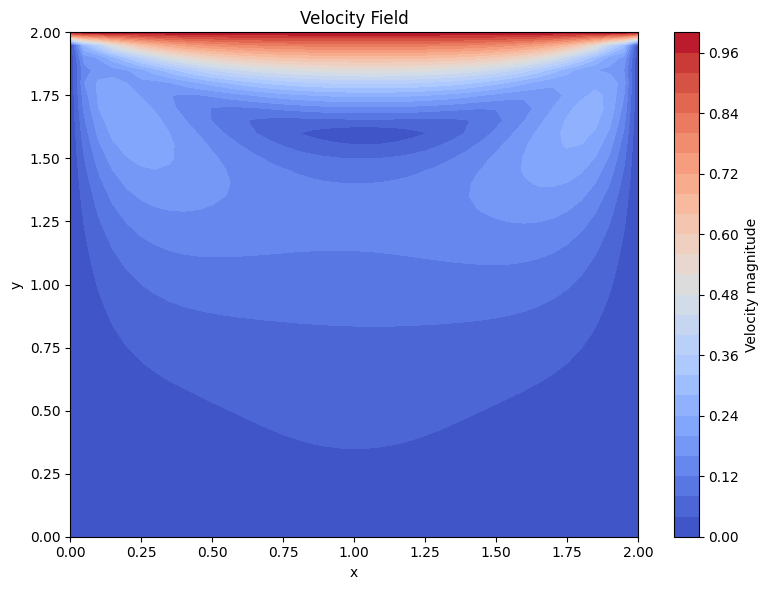

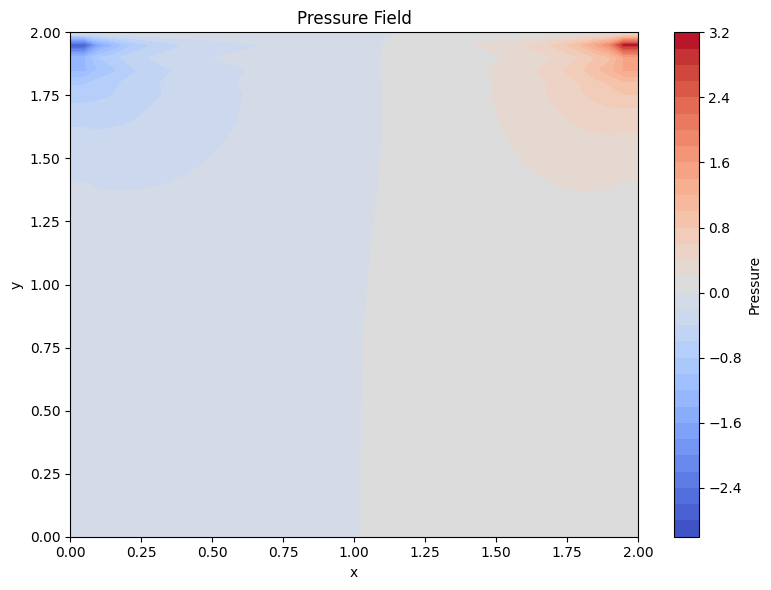

In [3]:
# 2D Lid-Driven Cavity Flow

import numpy as np
import matplotlib.pyplot as plt

#1.Define the computational domain
nx=41  # the number of grid points in x-axis
ny=41  # the number of grid points in y-axis 
nt=500 # the number of time steps
nit=50 # pressure iteration steps

Lx=2   # domain length in x-direction
Ly=2   # domain length in y-direction

dx=Lx/(nx-1)
dy=Ly/(ny-1)

rho=1.0 # fluid density
nu=0.1  # kinetic energy
dt=0.001# time step

#2.Initialize velocity and pressure field
u=np.zeros((ny,nx)) #velocity in x-direction
v=np.zeros((ny,nx)) #velocity in y-direction
p=np.zeros((ny,nx)) #pressure field
b=np.zeros((ny,nx)) #Right hand side of pressure equation

#3.Construct the pressure source term

def build_up_b(b,rho,dt,u,v,dx,dy):
    dudx=(u[1:-1,2:]-u[1:-1,:-2])/(2*dx)
    dudy=(u[2:,1:-1]-u[:-2,1:-1])/(2*dy)
    dvdx=(v[1:-1,2:]-v[1:-1,:-2])/(2*dx)
    dvdy=(v[2:,1:-1]-v[:-2,1:-1])/(2*dy)
    
    divergence=dudx+dvdy
    
    b[1:-1,1:-1]=rho*(divergence/dt-dudx**2-2*dudy*dvdx-dvdy**2)
    return b

#4.Solve the pressure Poisson equation

def pressure_poisson(p, dx, dy, b):

    for _ in range(nit):

        # Save pressure from the previous iteration
        pn = p.copy()

        # Neighboring pressure values
        p_right = pn[1:-1, 2:]
        p_left = pn[1:-1, :-2]
        p_up = pn[2:, 1:-1]
        p_down = pn[:-2, 1:-1]

        # Calculate pressure
        term_x = (p_right + p_left) * dy**2
        term_y = (p_up + p_down) * dx**2

        denominator = 2 * (dx**2 + dy**2)

        source = (dx**2 * dy**2 / denominator) * b[1:-1, 1:-1]

        p[1:-1, 1:-1] = (term_x + term_y) / denominator - source

        # Pressure boundary conditions
        p[:, -1] = p[:, -2]  # Right
        p[:, 0] = p[:, 1]    # Left
        p[0, :] = p[1, :]    # Bottom
        p[-1, :] = 0         # Top

    return p

for n in range(nt):
    un=u.copy()
    vn=v.copy()
    #build the pressure source term
    b=build_up_b(b,rho,dt,un,vn,dx,dy)
    
    #Calculate pressure
    p=pressure_poisson(p,dx,dy,b)
    
    dudx=(un[1:-1,1:-1]-un[1:-1,:-2])/dx
    dudy=(un[1:-1,1:-1]-un[:-2,1:-1])/dy
    
    dvdx=(vn[1:-1,1:-1]-vn[1:-1,:-2])/dx
    dvdy=(vn[1:-1,1:-1]-vn[:-2,1:-1])/dy
    
    #Pressure gradients
    dpdx=(p[1:-1,2:]-p[1:-1,:-2])/(2*dx)
    dpdy=(p[2:,1:-1]-p[:-2,1:-1])/(2*dy)
    
    d2udx2=(un[1:-1,2:]-2*un[1:-1,1:-1]+un[1:-1,:-2])/dx**2
    d2udy2=(un[2:,1:-1]-2*un[1:-1,1:-1]+un[:-2,1:-1])/dy**2
    d2vdx2=(vn[1:-1,2:]-2*vn[1:-1,1:-1]+vn[1:-1,:-2])/dx**2
    d2vdy2=(vn[2:,1:-1]-2*vn[1:-1,1:-1]+vn[:-2,1:-1])/dy**2
    
    # Convection terms
    convection_u=-(un[1:-1,1:-1]*dudx+vn[1:-1,1:-1]*dudy)
    convection_v=-(un[1:-1,1:-1]*dvdx+vn[1:-1,1:-1]*dvdy)
    
    # Pressure gradient terms
    pressure_u=-dpdx/rho
    pressure_v=-dpdy/rho
    
    # Viscous diffusion terms
    diffusion_u=nu*(d2udx2+d2udy2)
    diffusion_v=nu*(d2vdx2+d2vdy2)
    
    # Update velocity components
    u[1:-1,1:-1]=un[1:-1,1:-1]+dt*(convection_u+pressure_u+diffusion_u)
    v[1:-1,1:-1]=vn[1:-1,1:-1]+dt*(convection_v+pressure_v+diffusion_v)
    
    # Velocity boundary conditions:
    u[0,:]=0.0
    u[:,0]=0.0
    u[:,-1]=0.0
    u[-1,:]=1
    
    v[0,:]=0.0
    v[:,0]=0.0
    v[:,-1]=0.0
    v[-1,:]=0.0
    
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
X, Y = np.meshgrid(x, y)

plt.figure(figsize=(8, 6))

speed = np.sqrt(u**2 + v**2)

plt.contourf(X, Y, speed, levels=30, cmap="coolwarm")

plt.colorbar(label="Velocity magnitude")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Velocity Field")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))

plt.contourf(X, Y, p, levels=30, cmap="coolwarm")

plt.colorbar(label="Pressure")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pressure Field")

plt.tight_layout()
plt.show()
